In [1]:

# ============================================================
# SECTION 1: IMPORTS AND USER SETTINGS
# ============================================================

from pathlib import Path
from datetime import timedelta
import re
import warnings

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from bs4 import BeautifulSoup
from astropy.io import fits
from astropy.coordinates import SkyCoord
import astropy.units as u

from sunpy.net import Fido, attrs as a
from sunpy.coordinates import HeliographicStonyhurst


# ---------------- USER SETTINGS ----------------

START_DATE = "2010-05-01 00:00:00"
END_DATE = "2011-12-31 23:59:59"

# Minimum GOES flare magnitude.
# Examples: "C1.0", "M1.0", "X1.0"
MIN_FLARE_CLASS = "M1.0"

# Include observations before and after the flare.
PRE_FLARE_MINUTES = 10
POST_FLARE_MINUTES = 20

# Location requirements.
REQUIRE_LOCATION = True

# Whether to retain catalogue duplicates in the
# working catalogue after reporting them.
REMOVE_EXACT_DUPLICATES = True

# Time tolerance used to identify possible duplicate
# catalogue entries (not automatically removed).
DUPLICATE_TIME_TOLERANCE_MIN = 10

# EVE Linesfit version.
EVE_VERSION = "008"

EVE_BASE_URL = (
    "https://lasp.colorado.edu/eve/data_access/"
    "eve_data/products/level4_linesfit"
)

# Output folders.
OUTPUT = Path("Solar_Flare_Project")

FITS_FOLDER = OUTPUT / "FITS"
CATALOGUE_FOLDER = OUTPUT / "Catalogues"
DATA_FOLDER = OUTPUT / "Flare_Data"
PLOT_FOLDER = OUTPUT / "Plots"

for folder in [
    OUTPUT, FITS_FOLDER, CATALOGUE_FOLDER,
    DATA_FOLDER, PLOT_FOLDER
]:
    folder.mkdir(parents=True, exist_ok=True)

# These variables will be populated by later sections.
flare_catalogue = None
filtered_flares = None
flare_measurements = {}


/Users/scottd/miniforge3/envs/sunpy-clean/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:

# ============================================================
# SECTION 2: DOWNLOAD HEK FLARE CATALOGUE
# ============================================================

def find_flares(start_date, end_date):

    print("Searching HEK...")

    result = Fido.search(
        a.Time(start_date, end_date),
        a.hek.EventType("FL"),
        a.hek.FL.GOESCls >= "C1.0",
    )

    hek = result["hek"]

    print("HEK entries found:", len(hek))

    records = []

    for i, event in enumerate(hek):

        def safe_get(column):

            if column not in hek.colnames:
                return None

            try:
                value = event[column]

                if np.ma.is_masked(value):
                    return None

                return value

            except Exception:
                return None

        record = {}

        record["catalogue_row"] = i

        # Event identity and detection information.
        for col in [
            "kb_archivid",
            "frm_name",
            "obs_observatory",
            "obs_instrument",
            "event_type",
            "event_description",
            "ar_noaanum"
        ]:
            record[col] = safe_get(col)

        # Event times.
        for col in [
            "event_starttime",
            "event_peaktime",
            "event_endtime"
        ]:

            value = safe_get(col)

            if value is not None:
                value = pd.to_datetime(
                    str(value), utc=True
                )

            record[col] = value

        # GOES classification.
        # Extract GOES classification safely
        goes_class = safe_get("fl_goescls")
        
        if goes_class is None:
            goes_class = safe_get("goes_class")
        
        if goes_class is None:
            goes_class = safe_get("event_description")
        
        record["fl_goescls"] = goes_class

        # Original event coordinates.
        coord = safe_get("event_coord")
        record["event_coord_obj"] = coord
        record["event_coord"] = str(coord)

        # Save HPC coordinates if available.
        record["hpc_x_arcsec"] = np.nan
        record["hpc_y_arcsec"] = np.nan

        if coord is not None:

            try:
                record["hpc_x_arcsec"] = (
                    coord.Tx.to_value(u.arcsec)
                )

                record["hpc_y_arcsec"] = (
                    coord.Ty.to_value(u.arcsec)
                )

            except Exception:
                pass

        # Save HGS coordinates if available.
        hgs = safe_get("hgs_coord")

        record["hgs_longitude_deg"] = np.nan
        record["hgs_latitude_deg"] = np.nan

        if hgs is not None:

            try:
                record["hgs_longitude_deg"] = (
                    hgs.lon.to_value(u.deg)
                )

                record["hgs_latitude_deg"] = (
                    hgs.lat.to_value(u.deg)
                )

            except Exception:
                pass

        # Retain any additional raw-style location fields.
        for col in [
            "hpc_x", "hpc_y",
            "hgs_x", "hgs_y",
            "event_coord1", "event_coord2",
            "event_coordsys"
        ]:
            record[col] = safe_get(col)

        records.append(record)

    df = pd.DataFrame(records)

    # Save the unfiltered catalogue.
    df.to_csv(
        CATALOGUE_FOLDER / "HEK_complete_catalogue.csv",
        index=False
    )

    print("Catalogue saved.")

    return df


# RUN SECTION 2:
flare_catalogue = find_flares(
    START_DATE,
    END_DATE
)

display(flare_catalogue.head())


Searching HEK...
HEK entries found: 3045
Catalogue saved.


,catalogue_row,kb_archivid,frm_name,obs_observatory,obs_instrument,event_type,event_description,ar_noaanum,event_starttime,event_peaktime,...,hpc_y_arcsec,hgs_longitude_deg,hgs_latitude_deg,hpc_x,hpc_y,hgs_x,hgs_y,event_coord1,event_coord2,event_coordsys
0,0,ivo://helio-informatics.org/FL_SSWLatestEvents...,SSW Latest Events,SDO,AIA,FL,,0,2010-05-01 01:34:00+00:00,2010-05-01 01:39:00+00:00,...,NaN,-80.99999999999994,23.999999999999996,-859.9380,396.5484,-81.0,24.0,None,None,None
1,1,ivo://helio-informatics.org/FL_SECstandard_201...,SWPC,GOES,GOES,FL,,11067,2010-05-01 01:34:00+00:00,2010-05-01 01:39:00+00:00,...,NaN,-73.0,23.0,-838.8540,390.0636,-73.0,23.0,None,None,None
2,2,ivo://helio-informatics.org/FL_SSWLatestEvents...,SSW Latest Events,SDO,AIA,FL,,0,2010-05-04 16:15:00+00:00,2010-05-04 16:29:00+00:00,...,NaN,23.000000000000014,41.0,281.4858,668.9760,23.0,41.0,None,None,None
3,3,ivo://helio-informatics.org/FL_SECstandard_201...,SWPC,GOES,GOES,FL,,11069,2010-05-04 16:15:00+00:00,2010-05-04 16:29:00+00:00,...,NaN,23.0,41.0,281.2860,668.4960,23.0,41.0,None,None,None
4,4,ivo://helio-informatics.org/FL_SSWLatestEvents...,SSW Latest Events,SDO,AIA,FL,,1069,2010-05-05 07:09:00+00:00,2010-05-05 07:16:00+00:00,...,NaN,30.999999999999993,41.0,370.8990,665.0400,31.0,41.0,None,None,None


In [4]:

# ============================================================
# SECTION 3: ROBUST GOES MAGNITUDE FILTER
# ============================================================

GOES_SCALE = {
    "A": 1e-8,
    "B": 1e-7,
    "C": 1e-6,
    "M": 1e-5,
    "X": 1e-4
}


def goes_to_flux(flare_class):

    if pd.isna(flare_class):
        return np.nan

    match = re.search(
        r"([ABCMX])\s*([0-9]+\.?[0-9]*)",
        str(flare_class).upper()
    )

    if match is None:
        return np.nan

    letter = match.group(1)
    magnitude = float(match.group(2))

    return GOES_SCALE[letter] * magnitude


def filter_flares(df, minimum_class):

    if df is None or df.empty:
        raise ValueError("The flare catalogue is empty.")

    # Check for the GOES classification column.
    if "fl_goescls" not in df.columns:

        print("Available columns:")
        print(df.columns.tolist())

        raise KeyError(
            "GOES classification column 'fl_goescls' "
            "is missing. Check Section 2."
        )

    threshold = goes_to_flux(minimum_class)

    if not np.isfinite(threshold):
        raise ValueError(
            f"Invalid GOES threshold: {minimum_class}"
        )

    result = df.copy()

    result["GOES_flux_W_m2"] = (
        result["fl_goescls"].apply(goes_to_flux)
    )

    # Report missing classifications.
    missing = result["GOES_flux_W_m2"].isna().sum()

    print("Total catalogue entries:", len(result))
    print("Missing GOES classifications:", missing)

    # Filter by magnitude.
    result = result[
        result["GOES_flux_W_m2"] >= threshold
    ].copy()

    result = result.reset_index(drop=True)

    result["flare_id"] = np.arange(
        1, len(result) + 1
    )

    print("\nGOES FILTER RESULTS")
    print("Minimum class:", minimum_class)
    print("Flares retained:", len(result))

    result.to_csv(
        CATALOGUE_FOLDER / "Filtered_flares.csv",
        index=False
    )

    return result


# RUN SECTION 3:

filtered_flares = filter_flares(
    flare_catalogue,
    MIN_FLARE_CLASS
)

display(filtered_flares.head())


Total catalogue entries: 3045
Missing GOES classifications: 1

GOES FILTER RESULTS
Minimum class: M1.0
Flares retained: 268


,catalogue_row,kb_archivid,frm_name,obs_observatory,obs_instrument,event_type,event_description,ar_noaanum,event_starttime,event_peaktime,...,hgs_latitude_deg,hpc_x,hpc_y,hgs_x,hgs_y,event_coord1,event_coord2,event_coordsys,GOES_flux_W_m2,flare_id
0,12,ivo://helio-informatics.org/FL_SSWLatestEvents...,SSW Latest Events,SDO,AIA,FL,,0,2010-05-05 17:13:00+00:00,2010-05-05 17:19:00+00:00,...,20.999999999999986,77.7402,399.1158,5.0,21.0,None,None,None,0.000012,1
1,13,ivo://helio-informatics.org/FL_SECstandard_201...,SWPC,GOES,GOES,FL,,11069,2010-05-05 17:13:00+00:00,2010-05-05 17:19:00+00:00,...,42.0,426.2958,673.0320,37.0,42.0,None,None,None,0.000012,2
2,23,ivo://helio-informatics.org/FL_SECstandard_201...,SWPC,GOES,GOES,FL,,11081,2010-06-12 00:30:00+00:00,2010-06-12 00:57:00+00:00,...,23.0,594.7092,363.0318,43.0,23.0,None,None,None,0.000020,3
3,24,ivo://helio-informatics.org/FL_SSWLatestEvents...,SSW Latest Events,SDO,AIA,FL,,1081,2010-06-12 00:30:00+00:00,2010-06-12 00:57:00+00:00,...,23.0,638.0700,363.6930,47.0,23.0,None,None,None,0.000020,4
4,31,ivo://helio-informatics.org/FL_SSWLatestEvents...,SSW Latest Events,SDO,AIA,FL,,1079,2010-06-13 05:30:00+00:00,2010-06-13 05:39:00+00:00,...,-24.0,855.3120,-386.1582,82.0,-24.0,None,None,None,0.000010,5


In [5]:

# ============================================================
# SECTION 4: CHECK CATALOGUE DUPLICATES AND TIME DIFFERENCES
# ============================================================

def compare_catalogue_entries(df):

    df = df.copy()

    df["duplicate_group"] = -1
    df["duplicate_status"] = "Unique"

    groups = []
    used = set()

    for i in range(len(df)):

        if i in used:
            continue

        group = [i]

        t1 = df.iloc[i]["event_starttime"]
        p1 = df.iloc[i]["event_peaktime"]
        e1 = df.iloc[i]["event_endtime"]

        if pd.isna(t1) or pd.isna(p1) or pd.isna(e1):
            continue

        for j in range(i + 1, len(df)):

            t2 = df.iloc[j]["event_starttime"]
            p2 = df.iloc[j]["event_peaktime"]
            e2 = df.iloc[j]["event_endtime"]

            if pd.isna(t2) or pd.isna(p2) or pd.isna(e2):
                continue

            peak_difference = abs(
                (p1 - p2).total_seconds() / 60
            )

            intervals_overlap = (
                t1 <= e2 and t2 <= e1
            )

            if (
                peak_difference <= DUPLICATE_TIME_TOLERANCE_MIN
                and intervals_overlap
            ):
                group.append(j)

        if len(group) > 1:

            used.update(group)

            groups.append(group)

    reports = []

    group_number = 0

    for group in groups:

        group_number += 1

        subset = df.iloc[group]

        for idx in group:
            df.loc[idx, "duplicate_group"] = group_number

        exact = subset[
            [
                "event_starttime",
                "event_peaktime",
                "event_endtime"
            ]
        ].drop_duplicates().shape[0] == 1

        for idx in group:

            df.loc[idx, "duplicate_status"] = (
                "Exact duplicate" if exact
                else "Possible duplicate - different times"
            )

        # Compare each entry against the first entry.
        reference = subset.iloc[0]

        for _, row in subset.iterrows():

            reports.append({

                "duplicate_group": group_number,

                "reference_catalogue_row":
                    reference["catalogue_row"],

                "compared_catalogue_row":
                    row["catalogue_row"],

                "reference_start":
                    reference["event_starttime"],

                "compared_start":
                    row["event_starttime"],

                "start_difference_seconds":
                    (
                        row["event_starttime"] -
                        reference["event_starttime"]
                    ).total_seconds(),

                "reference_peak":
                    reference["event_peaktime"],

                "compared_peak":
                    row["event_peaktime"],

                "peak_difference_seconds":
                    (
                        row["event_peaktime"] -
                        reference["event_peaktime"]
                    ).total_seconds(),

                "reference_end":
                    reference["event_endtime"],

                "compared_end":
                    row["event_endtime"],

                "end_difference_seconds":
                    (
                        row["event_endtime"] -
                        reference["event_endtime"]
                    ).total_seconds(),

                "reference_class":
                    reference["fl_goescls"],

                "compared_class":
                    row["fl_goescls"],

                "exact_duplicate": exact,

                "reference_algorithm":
                    reference["frm_name"],

                "compared_algorithm":
                    row["frm_name"]
            })

    report = pd.DataFrame(reports)

    report.to_csv(
        CATALOGUE_FOLDER / "Duplicate_comparison.csv",
        index=False
    )

    df.to_csv(
        CATALOGUE_FOLDER / "Catalogue_duplicate_flags.csv",
        index=False
    )

    print("Possible duplicate groups:", len(groups))

    if not report.empty:
        display(report)

    # Remove only entries with identical three event times.
    if REMOVE_EXACT_DUPLICATES:

        exact_duplicate_rows = (
            df["duplicate_status"] == "Exact duplicate"
        )

        # Keep the first row in each exact-duplicate group.
        remove_indices = []

        for group_id in df.loc[
            exact_duplicate_rows, "duplicate_group"
        ].unique():

            indices = df.index[
                df["duplicate_group"] == group_id
            ].tolist()

            remove_indices.extend(indices[1:])

        df = df.drop(index=remove_indices)

    df = df.reset_index(drop=True)

    print("Entries remaining:", len(df))

    return df, report


# RUN SECTION 4:
filtered_flares, duplicate_report = compare_catalogue_entries(
    filtered_flares
)


Possible duplicate groups: 118


,duplicate_group,reference_catalogue_row,compared_catalogue_row,reference_start,compared_start,start_difference_seconds,reference_peak,compared_peak,peak_difference_seconds,reference_end,compared_end,end_difference_seconds,reference_class,compared_class,exact_duplicate,reference_algorithm,compared_algorithm
0,1,12,12,2010-05-05 17:13:00+00:00,2010-05-05 17:13:00+00:00,0.0,2010-05-05 17:19:00+00:00,2010-05-05 17:19:00+00:00,0.0,2010-05-05 17:22:00+00:00,2010-05-05 17:22:00+00:00,0.0,M1.2,M1.2,True,SSW Latest Events,SSW Latest Events
1,1,12,13,2010-05-05 17:13:00+00:00,2010-05-05 17:13:00+00:00,0.0,2010-05-05 17:19:00+00:00,2010-05-05 17:19:00+00:00,0.0,2010-05-05 17:22:00+00:00,2010-05-05 17:22:00+00:00,0.0,M1.2,M1.2,True,SSW Latest Events,SWPC
2,2,23,23,2010-06-12 00:30:00+00:00,2010-06-12 00:30:00+00:00,0.0,2010-06-12 00:57:00+00:00,2010-06-12 00:57:00+00:00,0.0,2010-06-12 01:02:00+00:00,2010-06-12 01:02:00+00:00,0.0,M2.0,M2.0,True,SWPC,SWPC
3,2,23,24,2010-06-12 00:30:00+00:00,2010-06-12 00:30:00+00:00,0.0,2010-06-12 00:57:00+00:00,2010-06-12 00:57:00+00:00,0.0,2010-06-12 01:02:00+00:00,2010-06-12 01:02:00+00:00,0.0,M2.0,M2.0,True,SWPC,SSW Latest Events
4,3,31,31,2010-06-13 05:30:00+00:00,2010-06-13 05:30:00+00:00,0.0,2010-06-13 05:39:00+00:00,2010-06-13 05:39:00+00:00,0.0,2010-06-13 05:39:00+00:00,2010-06-13 05:39:00+00:00,0.0,M1.0,M1.0,False,SSW Latest Events,SSW Latest Events
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
246,116,3012,3013,2011-12-30 03:03:00+00:00,2011-12-30 03:03:00+00:00,0.0,2011-12-30 03:09:00+00:00,2011-12-30 03:09:00+00:00,0.0,2011-12-30 03:13:00+00:00,2011-12-30 03:13:00+00:00,0.0,M1.2,M1.2,True,SSW Latest Events,SWPC
247,117,3038,3038,2011-12-31 13:09:00+00:00,2011-12-31 13:09:00+00:00,0.0,2011-12-31 13:15:00+00:00,2011-12-31 13:15:00+00:00,0.0,2011-12-31 13:19:00+00:00,2011-12-31 13:19:00+00:00,0.0,M2.4,M2.4,True,SSW Latest Events,SSW Latest Events
248,117,3038,3039,2011-12-31 13:09:00+00:00,2011-12-31 13:09:00+00:00,0.0,2011-12-31 13:15:00+00:00,2011-12-31 13:15:00+00:00,0.0,2011-12-31 13:19:00+00:00,2011-12-31 13:19:00+00:00,0.0,M2.4,M2.4,True,SSW Latest Events,SWPC
249,118,3040,3040,2011-12-31 16:16:00+00:00,2011-12-31 16:16:00+00:00,0.0,2011-12-31 16:26:00+00:00,2011-12-31 16:26:00+00:00,0.0,2011-12-31 16:34:00+00:00,2011-12-31 16:34:00+00:00,0.0,M1.5,M1.5,True,SSW Latest Events,SSW Latest Events


Entries remaining: 186


In [6]:

# ============================================================
# SECTION 5: LOCATION VALIDATION AND COORDINATE CONVERSION
# ============================================================

def validate_locations(df):

    df = df.copy()

    location_results = []

    for idx, row in df.iterrows():

        x = row["hpc_x_arcsec"]
        y = row["hpc_y_arcsec"]

        lon = row["hgs_longitude_deg"]
        lat = row["hgs_latitude_deg"]

        has_hpc = (
            pd.notna(x) and pd.notna(y)
        )

        has_hgs = (
            pd.notna(lon) and pd.notna(lat)
        )

        # Attempt conversion from HPC to HGS.
        if has_hpc and not has_hgs:

            original_coord = row["event_coord"]

            try:

                # Recover the original SkyCoord from HEK.
                coord = row["event_coord_obj"]

                hgs = coord.transform_to(
                    HeliographicStonyhurst(
                        obstime=coord.obstime
                    )
                )

                lon = hgs.lon.to_value(u.deg)
                lat = hgs.lat.to_value(u.deg)

                df.loc[idx, "hgs_longitude_deg"] = lon
                df.loc[idx, "hgs_latitude_deg"] = lat

                has_hgs = True

            except Exception as error:

                print(
                    "HGS conversion failed for row",
                    row["catalogue_row"],
                    error
                )

        if has_hpc and has_hgs:
            status = "HPC and HGS available"

        elif has_hpc:
            status = "HPC only"

        elif has_hgs:
            status = "HGS only"

        else:
            status = "NO LOCATION DATA"

        location_results.append({

            "catalogue_row": row["catalogue_row"],

            "flare_id": row.get("flare_id", np.nan),

            "has_HPC": has_hpc,

            "has_HGS": has_hgs,

            "location_status": status,

            "HPC_x_arcsec": x,

            "HPC_y_arcsec": y,

            "HGS_longitude_deg": lon,

            "HGS_latitude_deg": lat
        })

    location_df = pd.DataFrame(location_results)

    location_df.to_csv(
        CATALOGUE_FOLDER / "Location_validation.csv",
        index=False
    )

    print("\nLOCATION VALIDATION")
    print(location_df["location_status"].value_counts())

    return df, location_df


# Save the SkyCoord objects from the original HEK search.

# RUN SECTION 5:
filtered_flares, location_report = validate_locations(
    filtered_flares
)

if REQUIRE_LOCATION:

    valid_location_ids = location_report.loc[
        location_report["has_HPC"] |
        location_report["has_HGS"],
        "catalogue_row"
    ]

    filtered_flares = filtered_flares[
        filtered_flares["catalogue_row"].isin(
            valid_location_ids
        )
    ].reset_index(drop=True)

    print(
        "Flares remaining after location filter:",
        len(filtered_flares)
    )



LOCATION VALIDATION
location_status
HGS only    186
Name: count, dtype: int64
Flares remaining after location filter: 186


In [7]:

# ============================================================
# SECTION 6: DOWNLOAD EVE LINESFIT FILES
# ============================================================

def download_eve_file(date):

    date = pd.Timestamp(date)

    year = date.year
    doy = date.dayofyear

    year_url = f"{EVE_BASE_URL}/{year}/"

    pattern = re.compile(
        rf"EVE_LINESFIT_L4_{year}{doy:03d}_"
        rf"{EVE_VERSION}_(\d+)\.fit"
    )

    print("Searching for:", date.date())

    response = requests.get(
        year_url,
        timeout=60
    )

    response.raise_for_status()

    filenames = re.findall(
        r'href=["\']([^"\']+\.fit)["\']',
        response.text,
        flags=re.IGNORECASE
    )

    matches = []

    for filename in filenames:

        match = pattern.fullmatch(
            filename.split("/")[-1]
        )

        if match:
            matches.append(
                (int(match.group(1)), filename)
            )

    if not matches:

        print("No EVE file found for", date.date())

        return None

    # Select the newest revision.
    revision, filename = max(matches)

    local_file = FITS_FOLDER / filename

    if local_file.exists():

        print("Already downloaded:", filename)

        return local_file

    url = year_url + filename

    print("Downloading:", filename)

    with requests.get(
        url,
        stream=True,
        timeout=120
    ) as response:

        response.raise_for_status()

        with open(local_file, "wb") as output_file:

            for chunk in response.iter_content(
                chunk_size=1024 * 1024
            ):

                if chunk:
                    output_file.write(chunk)

    print("Download complete.")

    return local_file


# RUN SECTION 6:
# Test one flare before downloading everything.

TEST_FLARE_ID = 1

test_flare = filtered_flares[
    filtered_flares["flare_id"] == TEST_FLARE_ID
].iloc[0]

test_file = download_eve_file(
    test_flare["event_peaktime"]
)

print(test_file)


Searching for: 2010-05-05
Downloading: EVE_LINESFIT_L4_2010125_008_01.fit
Download complete.
Solar_Flare_Project/FITS/EVE_LINESFIT_L4_2010125_008_01.fit


In [8]:

# ============================================================
# SECTION 7: INSPECT FITS FILE STRUCTURE
# ============================================================

def inspect_fits_file(filepath):

    with fits.open(filepath) as hdul:

        print("\nFITS STRUCTURE")
        print("=" * 60)

        hdul.info()

        for hdu in hdul:

            print("\nHDU:", hdu.name)

            if hdu.data is None:
                continue

            if hdu.data.dtype.names:

                print("Columns:")

                for name in hdu.data.dtype.names:

                    array = np.asarray(
                        hdu.data[name]
                    )

                    print(
                        name,
                        "| shape:", array.shape,
                        "| dtype:", array.dtype
                    )

            else:

                print("Array shape:", hdu.data.shape)


# RUN SECTION 7:
inspect_fits_file(test_file)



FITS STRUCTURE
Filename: Solar_Flare_Project/FITS/EVE_LINESFIT_L4_2010125_008_01.fit
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1  LinesMeta     1 BinTableHDU     41   70R x 7C   [E, E, E, E, E, 18A, 30A]   
  2  LinesFitParams    1 BinTableHDU     84   1440R x 18C   [70E, 70E, 70E, 140E, 70E, 70E, 70E, 70E, 140E, 70E, 70E, 70E, 70E, 70E, 70E, 70E, 70E, 70B]   
  3  FlareFitParams    1 BinTableHDU     72   1440R x 14C   [E, E, E, I, D, 70E, 70E, 70E, 140E, 70E, 70E, 70E, 140E, 70B]   
  4  LinesFitAccuracy    1 BinTableHDU     25   1R x 1C   [100800E]   
  5  LinesData     1 BinTableHDU    100   1R x 6C   [1440D, 1440J, 1440D, 1440I, 1440I, 100800E]   

HDU: PRIMARY

HDU: LinesMeta
Columns:
LINE_WAVELENGTH | shape: (70,) | dtype: >f4
LINE_TEMP_MK | shape: (70,) | dtype: >f4
LINE_TEMP_MIN | shape: (70,) | dtype: >f4
LINE_TEMP_MAX | shape: (70,) | dtype: >f4
BLEND_ERROR | shape: (70,) | dtype: >f4
LINE_ELEMENTS | sh

In [9]:

# ============================================================
# SECTION 8: EXTRACT EVE LINESFIT DATA
# ============================================================

def get_value_at_time_line(array,time_index,line_index):

    array = np.asarray(array)

    # Remove leading singleton dimensions only.
    while array.ndim > 1 and array.shape[0] == 1:
        array = array[0]

    if array.ndim == 1:
        return array[time_index]

    if array.ndim >= 2:
        return array[time_index, line_index]

    raise ValueError(
        f"Unexpected array shape: {array.shape}"
    )


def flatten_value(name, value):

    value = np.asarray(value)

    output = {}

    if value.ndim == 0:

        output[name] = value.item()

    else:

        for i, item in enumerate(value.flatten()):

            output[f"{name}_{i}"] = item.item()

    return output


def extract_daily_linesfit(filepath, flare):

    records = []

    with fits.open(filepath, memmap=False) as hdul:

        meta = hdul["LINESMETA"].data

        normal_fits = hdul["LINESFITPARAMS"].data

        flare_fits = hdul["FLAREFITPARAMS"].data

        line_data = hdul["LINESDATA"].data

        accuracy_data = hdul["LINESFITACCURACY"].data

        n_lines = len(meta)

        # Extract UTC seconds of day.
        sod = np.asarray(
            line_data["SOD"]
        ).flatten()

        n_times = len(sod)

        # Daily UTC timestamps.
        date = pd.Timestamp(
            filepath.name.split("_")[3][:4] + "-01-01",
            tz="UTC"
        )

        # More robustly determine the day from the filename.
        match = re.search(
            r"_(\d{4})(\d{3})_",
            filepath.name
        )

        year = int(match.group(1))
        doy = int(match.group(2))

        date = (
            pd.Timestamp(year=year, month=1, day=1, tz="UTC")
            + pd.Timedelta(days=doy - 1)
        )

        times = date + pd.to_timedelta(sod, unit="s")

        # Select the flare time window.
        window_start = (
            flare["event_starttime"] -
            pd.Timedelta(minutes=PRE_FLARE_MINUTES)
        )

        window_end = (
            flare["event_endtime"] +
            pd.Timedelta(minutes=POST_FLARE_MINUTES)
        )

        time_indices = np.where(
            (times >= window_start) &
            (times <= window_end)
        )[0]

        if len(time_indices) == 0:
            return records

        # Extract irradiance.
        irradiance_array = np.asarray(
            line_data["LINE_IRRADIANCE"]
        )

        while irradiance_array.ndim > 2:
            irradiance_array = irradiance_array[0]

        # Accuracy array is indexed line, time in the
        # published documentation.
        accuracy_array = np.asarray(
            accuracy_data["FIT_ACCURACY"]
        ).squeeze()

        if accuracy_array.shape == (n_lines, n_times):
            accuracy_array = accuracy_array.T

        elif accuracy_array.shape != (n_times, n_lines):

            warnings.warn(
                "Unexpected FIT_ACCURACY shape: "
                + str(accuracy_array.shape)
            )

            accuracy_array = None

        # Loop through observations and spectral lines.
        for ti in time_indices:

            for li in range(n_lines):

                record = {

                    "flare_id": flare["flare_id"],

                    "GOES_class": flare["fl_goescls"],

                    "time_utc": times[ti],

                    "line_index": li,

                }

                # ------------------------------
                # LINE METADATA
                # ------------------------------

                for column in meta.names:

                    record[column] = meta[column][li]

                # ------------------------------
                # LINESFITPARAMS HDU
                # ------------------------------

                for column in normal_fits.names:

                    value = get_value_at_time_line(
                        normal_fits[column], ti, li
                    )

                    record.update(
                        flatten_value(
                            "LINEFIT_" + column,
                            value
                        )
                    )

                # ------------------------------
                # FLAREFITPARAMS HDU
                # ------------------------------

                for column in flare_fits.names:

                    value = get_value_at_time_line(
                        flare_fits[column], ti, li
                    )

                    record.update(
                        flatten_value(
                            "FLAREFIT_" + column,
                            value
                        )
                    )

                # ------------------------------
                # LINE IRRADIANCE
                # ------------------------------

                record["LINE_IRRADIANCE"] = (
                    irradiance_array[ti, li]
                )

                # ------------------------------
                # FIT ACCURACY
                # ------------------------------

                if accuracy_array is not None:

                    record["FIT_ACCURACY"] = (
                        accuracy_array[ti, li]
                    )

                # ------------------------------
                # FLARE LOCATION
                # ------------------------------

                record["HPC_x_arcsec"] = (
                    flare["hpc_x_arcsec"]
                )

                record["HPC_y_arcsec"] = (
                    flare["hpc_y_arcsec"]
                )

                record["HGS_longitude_deg"] = (
                    flare["hgs_longitude_deg"]
                )

                record["HGS_latitude_deg"] = (
                    flare["hgs_latitude_deg"]
                )

                records.append(record)

    return records


# RUN SECTION 8:
test_records = extract_daily_linesfit(
    test_file,
    test_flare
)

test_df = pd.DataFrame(test_records)

display(test_df.head())

print("Rows extracted:", len(test_df))
print("Columns extracted:", len(test_df.columns))


,flare_id,GOES_class,time_utc,line_index,LINE_WAVELENGTH,LINE_TEMP_MK,LINE_TEMP_MIN,LINE_TEMP_MAX,BLEND_ERROR,LINE_ELEMENTS,...,FLAREFIT_ERR_AMPLITUDE,FLAREFIT_ERR_BACKGROUND_0,FLAREFIT_ERR_BACKGROUND_1,FLAREFIT_FIT_VALID,LINE_IRRADIANCE,FIT_ACCURACY,HPC_x_arcsec,HPC_y_arcsec,HGS_longitude_deg,HGS_latitude_deg
0,1,M1.2,2010-05-05 17:03:30.000000894+00:00,0,9.393,8.00,4.0,12.0,16.0,Fe (98%),...,-1.0,-1.0,-1.0,0,0.000001,0.253098,NaN,NaN,5.000000000000002,20.999999999999986
1,1,M1.2,2010-05-05 17:03:30.000000894+00:00,1,10.395,6.30,4.0,10.0,861.0,Fe (98%),...,-1.0,-1.0,-1.0,0,0.000004,0.037768,NaN,NaN,5.000000000000002,20.999999999999986
2,1,M1.2,2010-05-05 17:03:30.000000894+00:00,2,11.723,10.00,10.0,20.0,636.0,Fe (92%),...,-1.0,-1.0,-1.0,0,0.000002,0.053214,NaN,NaN,5.000000000000002,20.999999999999986
3,1,M1.2,2010-05-05 17:03:30.000000894+00:00,3,12.875,12.00,6.3,20.0,316.0,Fe (99%),...,-1.0,-1.0,-1.0,0,-1.000000,-1.000000,NaN,NaN,5.000000000000002,20.999999999999986
4,1,M1.2,2010-05-05 17:03:30.000000894+00:00,4,13.113,0.63,0.4,1.0,27.0,Fe (95%),...,-1.0,-1.0,-1.0,0,0.000002,0.029575,NaN,NaN,5.000000000000002,20.999999999999986


Rows extracted: 2730
Columns extracted: 53


In [10]:

# ============================================================
# SECTION 9: PROCESS ALL SELECTED FLARES
# ============================================================

def process_all_flares(df):

    all_results = {}

    for _, flare in df.iterrows():

        flare_id = int(flare["flare_id"])

        print("\n" + "=" * 60)
        print("Processing flare:", flare_id)
        print("GOES class:", flare["fl_goescls"])
        print("Peak:", flare["event_peaktime"])

        start = (
            flare["event_starttime"] -
            pd.Timedelta(minutes=PRE_FLARE_MINUTES)
        )

        end = (
            flare["event_endtime"] +
            pd.Timedelta(minutes=POST_FLARE_MINUTES)
        )

        # Identify all UTC days required.
        days = pd.date_range(
            start=start.normalize(),
            end=end.normalize(),
            freq="D"
        )

        flare_records = []

        for day in days:

            filepath = download_eve_file(day)

            if filepath is None:
                continue

            try:

                daily_records = extract_daily_linesfit(
                    filepath,
                    flare
                )

                flare_records.extend(daily_records)

            except Exception as error:

                print(
                    "Extraction error:",
                    day.date(),
                    error
                )

        if not flare_records:

            print("No measurements extracted.")

            continue

        flare_df = pd.DataFrame(flare_records)

        flare_df = flare_df.sort_values(
            ["time_utc", "line_index"]
        )

        output_file = (
            DATA_FOLDER /
            f"flare_{flare_id:04d}_"
            f"{flare['event_peaktime'].strftime('%Y%m%d_%H%M')}.csv"
        )

        flare_df.to_csv(
            output_file,
            index=False
        )

        all_results[flare_id] = flare_df

        print("Saved:", output_file)
        print("Rows:", len(flare_df))
        print("Lines:", flare_df["line_index"].nunique())

    return all_results


# RUN SECTION 9:
flare_measurements = process_all_flares(
    filtered_flares
)



Processing flare: 1
GOES class: M1.2
Peak: 2010-05-05 17:19:00+00:00
Searching for: 2010-05-05
Already downloaded: EVE_LINESFIT_L4_2010125_008_01.fit
Saved: Solar_Flare_Project/Flare_Data/flare_0001_20100505_1719.csv
Rows: 2730
Lines: 70

Processing flare: 3
GOES class: M2.0
Peak: 2010-06-12 00:57:00+00:00
Searching for: 2010-06-12
Downloading: EVE_LINESFIT_L4_2010163_008_01.fit
Download complete.
Saved: Solar_Flare_Project/Flare_Data/flare_0003_20100612_0057.csv
Rows: 4340
Lines: 70

Processing flare: 5
GOES class: M1.0
Peak: 2010-06-13 05:39:00+00:00
Searching for: 2010-06-13
Downloading: EVE_LINESFIT_L4_2010164_008_01.fit
Download complete.
Saved: Solar_Flare_Project/Flare_Data/flare_0005_20100613_0539.csv
Rows: 2730
Lines: 70

Processing flare: 6
GOES class: M1.0
Peak: 2010-06-13 05:39:00+00:00
Searching for: 2010-06-13
Already downloaded: EVE_LINESFIT_L4_2010164_008_01.fit
Saved: Solar_Flare_Project/Flare_Data/flare_0006_20100613_0539.csv
Rows: 3080
Lines: 70

Processing flare: 7

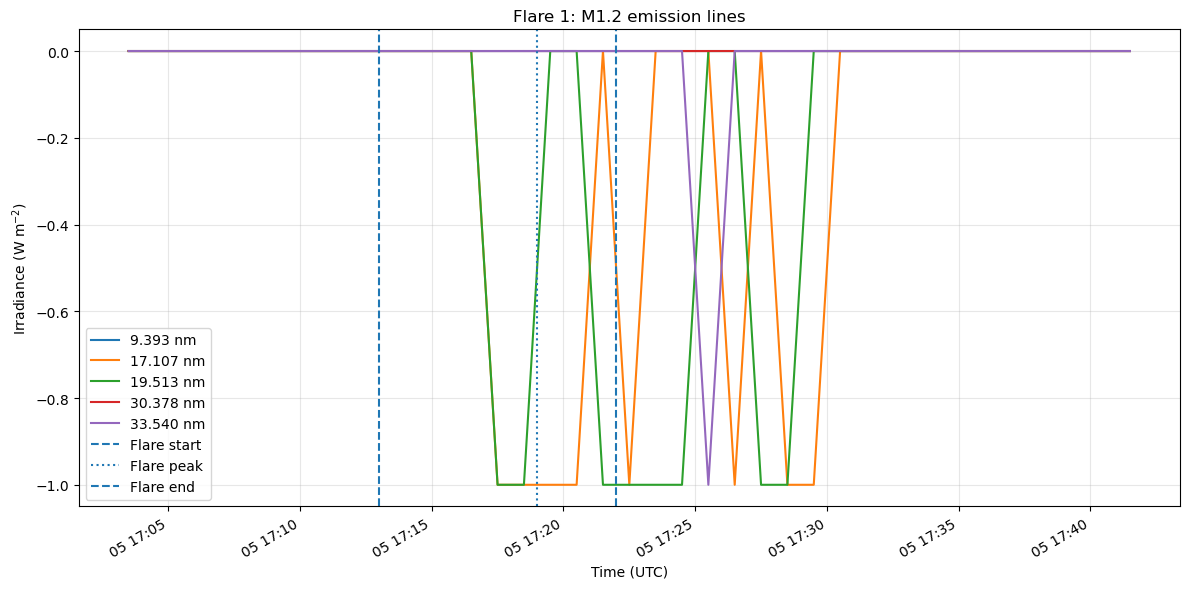

Flare not loaded: 2


In [11]:

# ============================================================
# SECTION 10: PLOT SELECTED EMISSION LINES
# ============================================================

def plot_flare_lines(
    flare_ids,
    wavelengths,
    irradiance_column="FLAREFIT_FLARE_IRRADIANCE",
    save_plots=True
):

    for flare_id in flare_ids:

        if flare_id not in flare_measurements:

            print("Flare not loaded:", flare_id)

            continue

        df = flare_measurements[flare_id].copy()

        fig, ax = plt.subplots(
            figsize=(12, 6)
        )

        for wavelength in wavelengths:

            # Find the closest available line.
            available = (
                df[
                    [
                        "LINE_WAVELENGTH",
                        "line_index"
                    ]
                ]
                .drop_duplicates()
                .dropna()
            )

            closest = available.iloc[
                np.argmin(
                    np.abs(
                        available["LINE_WAVELENGTH"].values
                        - wavelength
                    )
                )
            ]

            actual_wavelength = closest["LINE_WAVELENGTH"]

            line_index = int(closest["line_index"])

            tolerance = 0.02

            if abs(actual_wavelength - wavelength) > tolerance:

                print(
                    "Requested wavelength:",
                    wavelength,
                    "Closest available:",
                    actual_wavelength
                )

            line_df = df[
                df["line_index"] == line_index
            ].copy()

            line_df = line_df.sort_values("time_utc")

            if irradiance_column not in line_df.columns:

                print(
                    "Missing column:",
                    irradiance_column
                )

                continue

            line_df[irradiance_column] = pd.to_numeric(
                line_df[irradiance_column],
                errors="coerce"
            )

            ax.plot(
                line_df["time_utc"],
                line_df[irradiance_column],
                label=(
                    f"{actual_wavelength:.3f} nm"
                )
            )

        # Mark flare start, peak and end.
        flare = filtered_flares[
            filtered_flares["flare_id"] == flare_id
        ].iloc[0]

        ax.axvline(
            flare["event_starttime"],
            linestyle="--",
            label="Flare start"
        )

        ax.axvline(
            flare["event_peaktime"],
            linestyle=":",
            label="Flare peak"
        )

        ax.axvline(
            flare["event_endtime"],
            linestyle="--",
            label="Flare end"
        )

        ax.set_xlabel("Time (UTC)")

        ax.set_ylabel(
            "Irradiance (W m$^{-2}$)"
        )

        ax.set_title(
            f"Flare {flare_id}: "
            f"{flare['fl_goescls']} emission lines"
        )

        ax.legend()

        ax.grid(True, alpha=0.3)

        fig.autofmt_xdate()

        plt.tight_layout()

        if save_plots:

            fig.savefig(
                PLOT_FOLDER /
                f"flare_{flare_id:04d}_emission_lines.png",
                dpi=300
            )

        plt.show()


# ---------------- USER PLOT SETTINGS ----------------

SELECTED_FLARES = [1, 2]

SELECTED_WAVELENGTHS = [
    9.393,
    17.107,
    19.513,
    30.378,
    33.540
]

# Options:
# "LINE_IRRADIANCE"
# "FLAREFIT_FLARE_IRRADIANCE"
# "LINEFIT_AMPLITUDE"
# "FLAREFIT_FLARE_AMPLITUDE"

PLOT_COLUMN = "FLAREFIT_FLARE_IRRADIANCE"


# RUN SECTION 10:
plot_flare_lines(
    flare_ids=SELECTED_FLARES,
    wavelengths=SELECTED_WAVELENGTHS,
    irradiance_column=PLOT_COLUMN
)


In [12]:

# ============================================================
# SECTION 11: DATA QUALITY CHECKS
# ============================================================

def check_extracted_data(results):

    summary = []

    for flare_id, df in results.items():

        summary.append({

            "flare_id": flare_id,

            "number_of_observations":
                df["time_utc"].nunique(),

            "number_of_emission_lines":
                df["line_index"].nunique(),

            "number_of_rows":
                len(df),

            "preflare_background_available":
                "LINEFIT_BACKGROUND_0" in df.columns,

            "flare_irradiance_available":
                "FLAREFIT_FLARE_IRRADIANCE" in df.columns,

            "GOES_XRSB_available":
                "FLAREFIT_GOES_XRSB" in df.columns,

            "flare_flags_available":
                "FLAREFIT_FLARE_FLAG" in df.columns,

            "line_fit_validity_available":
                "LINEFIT_FIT_VALID" in df.columns,

            "flare_fit_validity_available":
                "FLAREFIT_FIT_VALID" in df.columns,

            "location_available":
                (
                    df["HPC_x_arcsec"].notna().any()
                    or df["HGS_longitude_deg"].notna().any()
                )

        })

    summary_df = pd.DataFrame(summary)

    summary_df.to_csv(
        OUTPUT / "Data_quality_report.csv",
        index=False
    )

    display(summary_df)

    return summary_df


# RUN SECTION 11:
quality_report = check_extracted_data(
    flare_measurements
)


,flare_id,number_of_observations,number_of_emission_lines,number_of_rows,preflare_background_available,flare_irradiance_available,GOES_XRSB_available,flare_flags_available,line_fit_validity_available,flare_fit_validity_available,location_available
0,1,39,70,2730,True,True,True,True,True,True,True
1,3,62,70,4340,True,True,True,True,True,True,True
2,5,39,70,2730,True,True,True,True,True,True,True
3,6,44,70,3080,True,True,True,True,True,True,True
4,7,44,70,3080,True,True,True,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...
181,259,51,70,3570,True,True,True,True,True,True,True
182,261,46,70,3220,True,True,True,True,True,True,True
183,263,40,70,2800,True,True,True,True,True,True,True
184,265,40,70,2800,True,True,True,True,True,True,True
